<a href="https://colab.research.google.com/github/kahrees/the-compendium/blob/main/Probability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Counting**

In [1]:
import jax.numpy as jnp
from math import factorial

n, r = 10, 3

perm = factorial(n) // factorial(n - r)
comb = factorial(n) // (factorial(r) * factorial(n - r))

print(f"P({n},{r}) = {perm}")
print(f"C({n},{r}) = {comb}")
print(f"P / C = {perm // comb} (should equal {r}! = {factorial(r)})")

P(10,3) = 720
C(10,3) = 120
P / C = 6 (should equal 3! = 6)


In [2]:
from itertools import combinations

def comb_count(n, r):
    return factorial(n) // (factorial(r) * factorial(n - r))

# Formula approach
men_ways = comb_count(8, 3)
women_ways = comb_count(6, 2)
print(f"Formula: {men_ways} × {women_ways} = {men_ways * women_ways}")

# Enumeration approach
men = [f"M{i}" for i in range(1, 9)]
women = [f"W{i}" for i in range(1, 7)]
count = sum(1 for _ in combinations(men, 3) for _ in combinations(women, 2))
print(f"Enumeration: {count}")

Formula: 56 × 15 = 840
Enumeration: 840


In [3]:
n = 26
r = 4

with_rep = n ** r
without_rep = factorial(n) // factorial(n - r)

print(f"With repetition:    {with_rep:>10,}")
print(f"Without repetition: {without_rep:>10,}")
print(f"Fraction with repeats: {1 - without_rep/with_rep:.2%}")

With repetition:       456,976
Without repetition:    358,800
Fraction with repeats: 21.48%


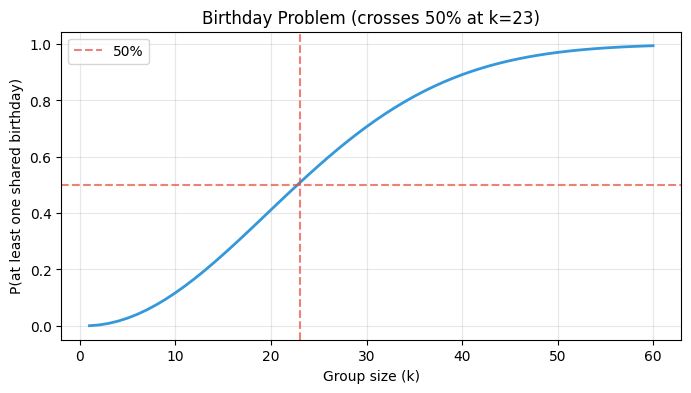

In [4]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

def birthday_prob_exact(k):
    """Probability of at least one shared birthday in group of k."""
    p_no_match = 1.0
    for i in range(k):
        p_no_match *= (365 - i) / 365
    return 1 - p_no_match

ks = list(range(1, 61))
probs = [birthday_prob_exact(k) for k in ks]

plt.figure(figsize=(8, 4))
plt.plot(ks, probs, color="#3498db", linewidth=2)
plt.axhline(y=0.5, color="#e74c3c", linestyle="--", alpha=0.7, label="50%")
cross = next(k for k, p in zip(ks, probs) if p >= 0.5)
plt.axvline(x=cross, color="#e74c3c", linestyle="--", alpha=0.7)
plt.xlabel("Group size (k)")
plt.ylabel("P(at least one shared birthday)")
plt.title(f"Birthday Problem (crosses 50% at k={cross})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Probability Concepts**

In [5]:
key = jax.random.PRNGKey(42)
n = 100_000

# Generate population
k1, k2 = jax.random.split(key)
has_disease = jax.random.bernoulli(k1, p=0.01, shape=(n,))

# Generate test results
k3, k4 = jax.random.split(k2)
# Sensitivity: P(+|D) = 0.95, Specificity: P(-|D') = 0.90
test_positive = jnp.where(
    has_disease,
    jax.random.bernoulli(k3, p=0.95, shape=(n,)),
    jax.random.bernoulli(k4, p=0.10, shape=(n,))
)

# Among those who tested positive, what fraction actually has the disease?
positives = test_positive.astype(bool)
true_positives = (has_disease & positives).sum()
total_positives = positives.sum()

print(f"Total positive tests: {total_positives}")
print(f"True positives: {true_positives}")
print(f"P(Disease | Positive) = {true_positives / total_positives:.4f}")
print(f"Bayes' formula:         {0.95 * 0.01 / 0.1085:.4f}")

Total positive tests: 10877
True positives: 944
P(Disease | Positive) = 0.0868
Bayes' formula:         0.0876


In [6]:

key = jax.random.PRNGKey(0)
n = 200_000
k1, k2 = jax.random.split(key)

# Events: A = value < 0.4, B = value < 0.6 (overlap at < 0.4)
vals_a = jax.random.uniform(k1, shape=(n,))
vals_b = jax.random.uniform(k2, shape=(n,))

A = vals_a < 0.4
B = vals_b < 0.6

p_a = A.mean()
p_b = B.mean()
p_a_and_b = (A & B).mean()
p_a_or_b = (A | B).mean()

print(f"P(A) = {p_a:.4f}")
print(f"P(B) = {p_b:.4f}")
print(f"P(A ∩ B) = {p_a_and_b:.4f}")
print(f"P(A ∪ B) simulated = {p_a_or_b:.4f}")
print(f"P(A) + P(B) - P(A∩B) = {p_a + p_b - p_a_and_b:.4f}")

P(A) = 0.4019
P(B) = 0.6002
P(A ∩ B) = 0.2413
P(A ∪ B) simulated = 0.7608
P(A) + P(B) - P(A∩B) = 0.7608


In [7]:
key = jax.random.PRNGKey(1)
n = 500_000
k1, k2 = jax.random.split(key)

d1 = jax.random.randint(k1, shape=(n,), minval=1, maxval=7)
d2 = jax.random.randint(k2, shape=(n,), minval=1, maxval=7)
total = d1 + d2

# Unconditional
p_sum7 = (total == 7).mean()
print(f"P(sum=7) = {p_sum7:.4f} (exact: {6/36:.4f})")

# Conditional on first die = 3
mask = d1 == 3
p_sum7_given_d1_3 = (total[mask] == 7).mean()
print(f"P(sum=7 | d1=3) = {p_sum7_given_d1_3:.4f} (exact: {1/6:.4f})")

P(sum=7) = 0.1660 (exact: 0.1667)
P(sum=7 | d1=3) = 0.1669 (exact: 0.1667)


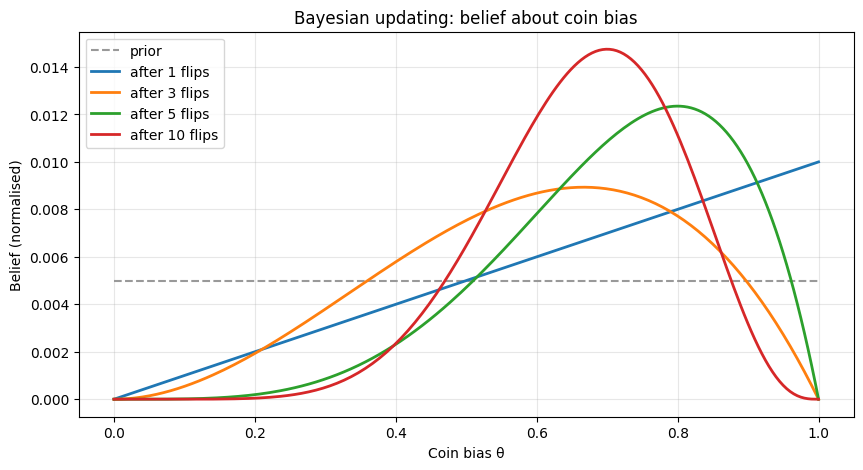

In [8]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

def bayes_update(prior, likelihood):
    """Multiply prior by likelihood and normalise."""
    posterior = prior * likelihood
    return posterior / posterior.sum()

# Discretise possible bias values
theta = jnp.linspace(0, 1, 200)
prior = jnp.ones_like(theta)  # uniform prior
prior = prior / prior.sum()

# Observed flips: 1=heads, 0=tails
flips = [1, 1, 0, 1, 1, 1, 0, 1, 0, 1]

plt.figure(figsize=(10, 5))
plt.plot(theta, prior, "--", color="#999", label="prior")

for i, flip in enumerate(flips):
    likelihood = theta if flip == 1 else (1 - theta)
    prior = bayes_update(prior, likelihood)
    if i in [0, 2, 4, 9]:
        plt.plot(theta, prior, label=f"after {i+1} flips", linewidth=2)

plt.xlabel("Coin bias θ")
plt.ylabel("Belief (normalised)")
plt.title("Bayesian updating: belief about coin bias")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Distributions**

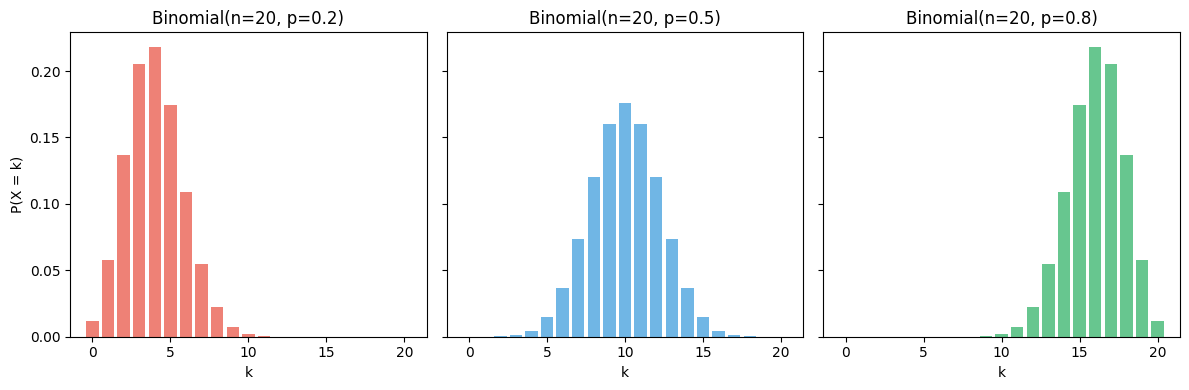

In [9]:
from math import comb

n = 20
ks = jnp.arange(0, n + 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, p, color in zip(axes, [0.2, 0.5, 0.8], ["#e74c3c", "#3498db", "#27ae60"]):
    pmf = jnp.array([comb(n, int(k)) * p**k * (1-p)**(n-k) for k in ks])
    ax.bar(ks, pmf, color=color, alpha=0.7)
    ax.set_title(f"Binomial(n={n}, p={p})")
    ax.set_xlabel("k")
axes[0].set_ylabel("P(X = k)")
plt.tight_layout()
plt.show()

In [11]:
from math import comb, factorial, exp

n, p = 1000, 0.003
lam = n * p
ks = jnp.arange(0, 15)

binom_pmf = jnp.array([comb(n, int(k)) * p**k * (1-p)**(n-k) for k in ks])
poisson_pmf = jnp.array([lam**k * exp(-lam) / factorial(int(k)) for k in ks])

plt.figure(figsize=(8, 4))
plt.bar(ks - 0.15, binom_pmf, width=0.3, color="#3498db", alpha=0.7, label=f"Binomial({n},{p})")
plt.bar(ks + 0.15, poisson_pmf, width=0.3, color="#e74c3c", alpha=0.7, label=f"Poisson({lam})")
plt.xlabel("k")
plt.ylabel("P(X = k)")
plt.title("Poisson approximation to Binomial")
plt.legend()
plt.show()

OverflowError: An overflow was encountered while parsing an argument to a jitted computation, whose argument path is x. Got <class 'int'> with value 41417124750

In [12]:
key = jax.random.PRNGKey(42)
mu, sigma = 5.0, 2.0
samples = mu + sigma * jax.random.normal(key, shape=(100_000,))

for k in [1, 2, 3]:
    within = jnp.abs(samples - mu) <= k * sigma
    print(f"Within {k}σ: {within.mean():.4f} (expected: {[0.6827, 0.9545, 0.9973][k-1]:.4f})")

Within 1σ: 0.6823 (expected: 0.6827)
Within 2σ: 0.9548 (expected: 0.9545)
Within 3σ: 0.9976 (expected: 0.9973)


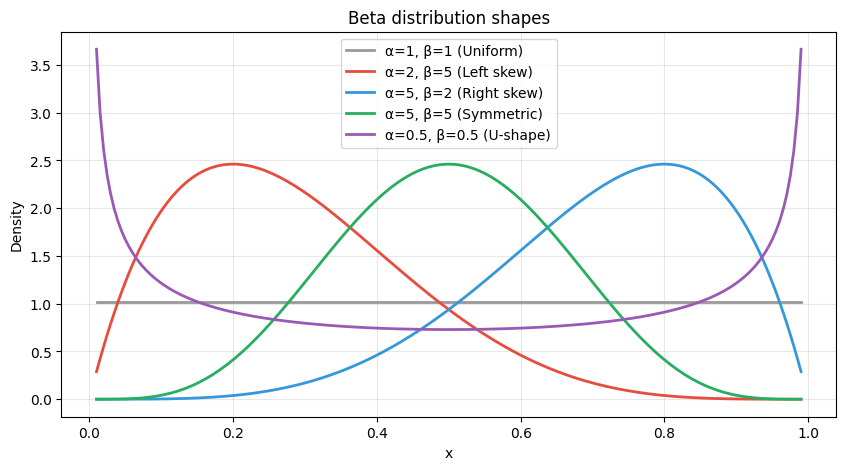

In [13]:
x = jnp.linspace(0.01, 0.99, 200)

def beta_pdf(x, a, b):
    # Unnormalised for shape comparison
    return x**(a-1) * (1-x)**(b-1)

plt.figure(figsize=(10, 5))
params = [(1,1,"Uniform"), (2,5,"Left skew"), (5,2,"Right skew"),
          (5,5,"Symmetric"), (0.5,0.5,"U-shape")]
colors = ["#999", "#e74c3c", "#3498db", "#27ae60", "#9b59b6"]

for (a, b, label), color in zip(params, colors):
    y = beta_pdf(x, a, b)
    y = y / jnp.trapezoid(y, x)  # normalise
    plt.plot(x, y, label=f"α={a}, β={b} ({label})", color=color, linewidth=2)

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Beta distribution shapes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Bayesian**

MLE: 0.7000
MAP (Beta(1,1)): 0.7000
MAP (Beta(2,2)): 0.6667
MAP (Beta(5,5)): 0.6111
MAP (Beta(10,10)): 0.5714


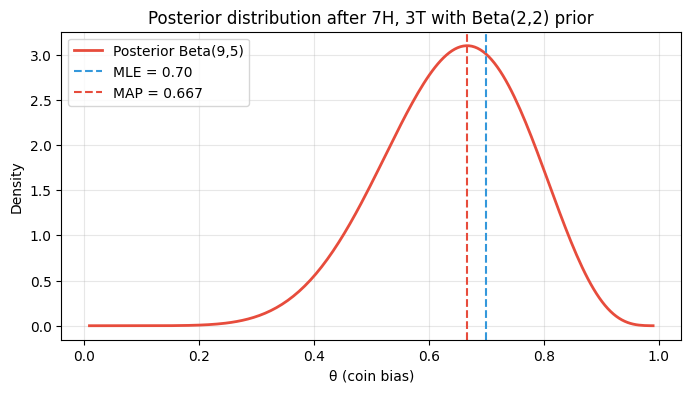

In [14]:

# Data: observed coin flips
heads, tails = 7, 3

# MLE
p_mle = heads / (heads + tails)
print(f"MLE: {p_mle:.4f}")

# MAP with Beta prior
for alpha, beta in [(1,1), (2,2), (5,5), (10,10)]:
    p_map = (alpha + heads - 1) / (alpha + beta + heads + tails - 2)
    print(f"MAP (Beta({alpha},{beta})): {p_map:.4f}")

# Visualise posterior for Beta(2,2) prior
theta = jnp.linspace(0.01, 0.99, 200)
# Posterior is Beta(alpha+heads, beta+tails)
a_post, b_post = 2 + heads, 2 + tails
posterior = theta**(a_post-1) * (1-theta)**(b_post-1)
posterior = posterior / jnp.trapezoid(posterior, theta)

plt.figure(figsize=(8, 4))
plt.plot(theta, posterior, color="#e74c3c", linewidth=2, label=f"Posterior Beta({a_post},{b_post})")
plt.axvline(p_mle, color="#3498db", linestyle="--", label=f"MLE = {p_mle:.2f}")
plt.axvline((a_post-1)/(a_post+b_post-2), color="#e74c3c", linestyle="--", label=f"MAP = {(a_post-1)/(a_post+b_post-2):.3f}")
plt.xlabel("θ (coin bias)")
plt.ylabel("Density")
plt.title("Posterior distribution after 7H, 3T with Beta(2,2) prior")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
# Transition matrix: R, S, C
T = jnp.array([
    [0.3, 0.4, 0.3],
    [0.2, 0.5, 0.3],
    [0.4, 0.3, 0.3]
])
states = ["Rainy", "Sunny", "Cloudy"]

# Simulate 100,000 steps
key = jax.random.PRNGKey(42)
n_steps = 100_000
state = 0  # start rainy
counts = jnp.zeros(3)

for i in range(n_steps):
    key, subkey = jax.random.split(key)
    state = jax.random.choice(subkey, 3, p=T[state])
    counts = counts.at[state].add(1)

sim_stationary = counts / n_steps
print("Simulated stationary distribution:")
for s, p in zip(states, sim_stationary):
    print(f"  {s}: {p:.4f}")

# Analytical: find left eigenvector with eigenvalue 1
eigenvalues, eigenvectors = jnp.linalg.eig(T.T)
idx = jnp.argmin(jnp.abs(eigenvalues - 1.0))
pi = jnp.real(eigenvectors[:, idx])
pi = pi / pi.sum()
print("\nAnalytical stationary distribution:")
for s, p in zip(states, pi):
    print(f"  {s}: {p:.4f}")

Simulated stationary distribution:
  Rainy: 0.2891
  Sunny: 0.4104
  Cloudy: 0.3005

Analytical stationary distribution:
  Rainy: 0.2889
  Sunny: 0.4111
  Cloudy: 0.3000


In [16]:

# HMM parameters
states = ["Rainy", "Sunny"]
obs_names = ["Umbrella", "No umbrella"]

trans = jnp.array([[0.7, 0.3],   # R->R, R->S
                    [0.4, 0.6]])  # S->R, S->S

emit = jnp.array([[0.9, 0.1],    # R->U, R->noU
                   [0.2, 0.8]])   # S->U, S->noU

init = jnp.array([0.5, 0.5])

# Observations: U=0, noU=1
observations = [0, 0, 1]  # Umbrella, Umbrella, No umbrella

def viterbi(obs, init, trans, emit):
    n_states = len(init)
    T = len(obs)
    V = jnp.zeros((T, n_states))
    path = jnp.zeros((T, n_states), dtype=int)

    # Initialisation
    V = V.at[0].set(init * emit[:, obs[0]])

    # Recursion
    for t in range(1, T):
        for j in range(n_states):
            probs = V[t-1] * trans[:, j]
            V = V.at[t, j].set(jnp.max(probs) * emit[j, obs[t]])
            path = path.at[t, j].set(jnp.argmax(probs))

    # Backtrack
    best = [int(jnp.argmax(V[-1]))]
    for t in range(T-1, 0, -1):
        best.insert(0, int(path[t, best[0]]))
    return best, V

decoded, scores = viterbi(observations, init, trans, emit)
print("Observations:", [obs_names[o] for o in observations])
print("Decoded:     ", [states[s] for s in decoded])

Observations: ['Umbrella', 'Umbrella', 'No umbrella']
Decoded:      ['Rainy', 'Rainy', 'Sunny']


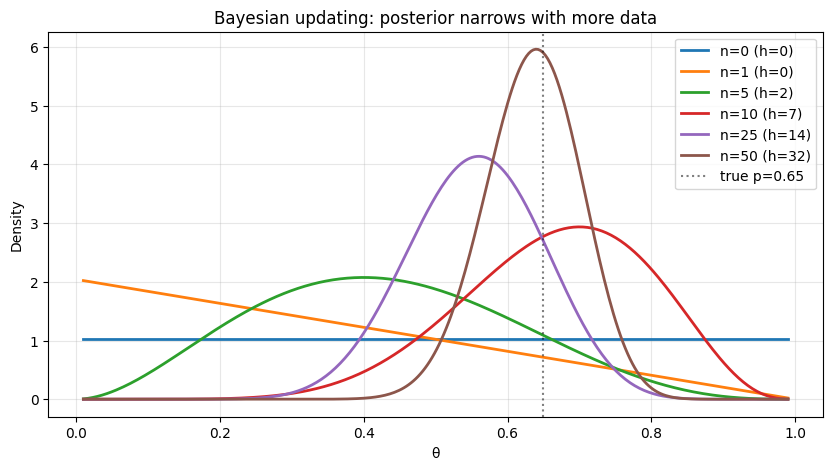

In [17]:


theta = jnp.linspace(0.01, 0.99, 300)
key = jax.random.PRNGKey(7)

# True bias = 0.65
flips = jax.random.bernoulli(key, p=0.65, shape=(50,))

plt.figure(figsize=(10, 5))
a, b = 1, 1  # Beta(1,1) = uniform

for n_obs in [0, 1, 5, 10, 25, 50]:
    h = int(flips[:n_obs].sum())
    t = n_obs - h
    a_post = a + h
    b_post = b + t
    y = theta**(a_post-1) * (1-theta)**(b_post-1)
    y = y / jnp.trapezoid(y, theta)
    plt.plot(theta, y, linewidth=2, label=f"n={n_obs} (h={h})")

plt.axvline(0.65, color="black", linestyle=":", alpha=0.5, label="true p=0.65")
plt.xlabel("θ")
plt.ylabel("Density")
plt.title("Bayesian updating: posterior narrows with more data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Information Theory**

In [18]:

def entropy(p):
    """Compute entropy in bits. Filter out zero-probability events."""
    p = p[p > 0]
    return -jnp.sum(p * jnp.log2(p))

# Fair die
fair = jnp.ones(6) / 6
print(f"Fair die entropy:   {entropy(fair):.4f} bits (max = log2(6) = {jnp.log2(6.):.4f})")

# Loaded die
loaded = jnp.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.5])
print(f"Loaded die entropy: {entropy(loaded):.4f} bits")

# Deterministic
det = jnp.array([0.0, 0.0, 0.0, 0.0, 0.0, 1.0])
print(f"Deterministic:      {entropy(det):.4f} bits")

# Fair coin
coin = jnp.array([0.5, 0.5])
print(f"Fair coin entropy:  {entropy(coin):.4f} bits")

Fair die entropy:   2.5850 bits (max = log2(6) = 2.5850)
Loaded die entropy: 2.1610 bits
Deterministic:      -0.0000 bits
Fair coin entropy:  1.0000 bits


In [19]:
def cross_entropy(p, q):
    return -jnp.sum(p * jnp.log2(jnp.clip(q, 1e-10, 1.0)))

def kl_divergence(p, q):
    mask = p > 0
    return jnp.sum(jnp.where(mask, p * jnp.log2(p / jnp.clip(q, 1e-10, 1.0)), 0.0))

def entropy(p):
    p = p[p > 0]
    return -jnp.sum(p * jnp.log2(p))

p = jnp.array([0.4, 0.3, 0.2, 0.1])  # true distribution

for name, q in [("perfect match", p),
                ("slight mismatch", jnp.array([0.35, 0.30, 0.25, 0.10])),
                ("big mismatch", jnp.array([0.1, 0.1, 0.1, 0.7]))]:
    h_p = entropy(p)
    h_pq = cross_entropy(p, q)
    kl = kl_divergence(p, q)
    print(f"{name:20s}: H(p)={h_p:.4f}, H(p,q)={h_pq:.4f}, "
          f"KL={kl:.4f}, H(p,q)-H(p)={h_pq-h_p:.4f}")

perfect match       : H(p)=1.8464, H(p,q)=1.8464, KL=0.0000, H(p,q)-H(p)=0.0000
slight mismatch     : H(p)=1.8464, H(p,q)=1.8591, KL=0.0127, H(p,q)-H(p)=0.0127
big mismatch        : H(p)=1.8464, H(p,q)=3.0412, KL=1.1948, H(p,q)-H(p)=1.1948


In [20]:
def kl_div(p, q):
    mask = p > 0
    return float(jnp.sum(jnp.where(mask, p * jnp.log2(p / jnp.clip(q, 1e-10, 1.0)), 0.0)))

p = jnp.array([0.9, 0.1])
q = jnp.array([0.5, 0.5])

print(f"D_KL(p || q) = {kl_div(p, q):.4f}")
print(f"D_KL(q || p) = {kl_div(q, p):.4f}")
print(f"Not the same! KL divergence is asymmetric.")

D_KL(p || q) = 0.5310
D_KL(q || p) = 0.7370
Not the same! KL divergence is asymmetric.


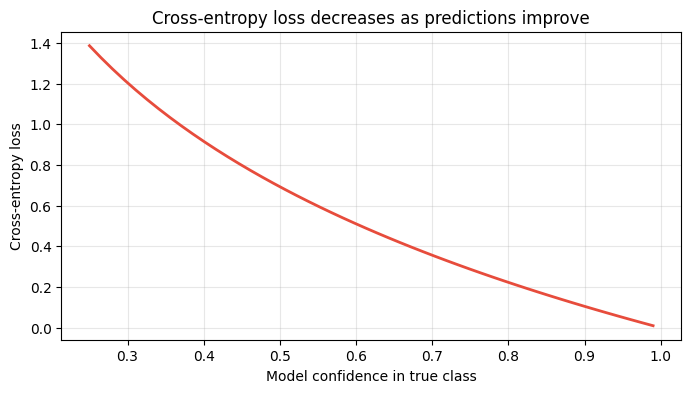

In [21]:
# True label: class 2 out of 4
true_label = jnp.array([0, 0, 1, 0])

# Simulate improving predictions
steps = []
losses = []
for confidence in jnp.linspace(0.25, 0.99, 50):
    # Model becomes more confident in class 2
    remaining = (1 - confidence) / 3
    pred = jnp.array([remaining, remaining, confidence, remaining])
    loss = -jnp.sum(true_label * jnp.log(jnp.clip(pred, 1e-10, 1.0)))
    steps.append(float(confidence))
    losses.append(float(loss))

plt.figure(figsize=(8, 4))
plt.plot(steps, losses, color="#e74c3c", linewidth=2)
plt.xlabel("Model confidence in true class")
plt.ylabel("Cross-entropy loss")
plt.title("Cross-entropy loss decreases as predictions improve")
plt.grid(alpha=0.3)
plt.show()